In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

SEG_DIR = Path("../data/segments_ecg")       

index = pd.read_csv(SEG_DIR / "index.csv")
print(index.shape, "| babies:", index["id"].nunique(), "| blocks:", len(index))
print("blocks per baby:", index.groupby("id").size().value_counts().sort_index().to_dict())

(1823, 4) | babies: 294 | blocks: 1823
blocks per baby: {1: 3, 2: 1, 3: 1, 4: 4, 5: 21, 6: 158, 7: 102, 8: 4}


Checked the first block (about 3 h of ECG) of 294 babies.
Share of ECG samples cut at the ±20 limit: typical baby 0.12%, worst baby 31.80% (id 171).
- 141 babies: almost nothing is cut (<0.1%), so the clip is harmless for them
- 127 babies: some peaks are cut (0.1% to 1%)
- 26 babies: most heartbeat peaks are cut (>1%), which is bad
=> The clip cuts real heartbeat peaks for many babies: change the normalization.


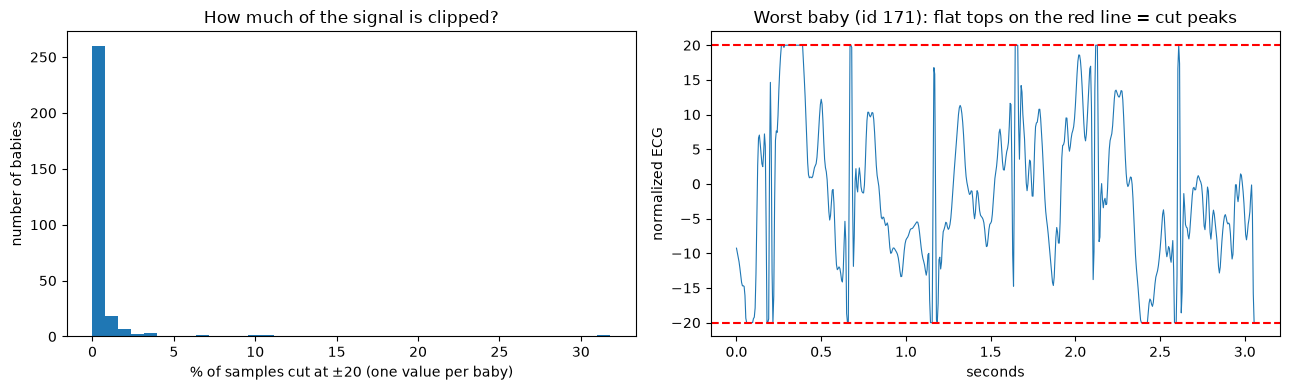

In [5]:
res = []
for _, r in index[index.segment == 1].iterrows():
    x = np.load(r["chemin"]).astype(np.float32)
    res.append((int(r["id"]), r["chemin"], (np.abs(x) >= 19.99).mean() * 100))
clip = pd.DataFrame(res, columns=["id", "path", "pct_clip"])

n     = len(clip)
none  = (clip.pct_clip < 0.1).sum()
some  = ((clip.pct_clip >= 0.1) & (clip.pct_clip < 1)).sum()
heavy = (clip.pct_clip >= 1).sum()
worst = clip.loc[clip.pct_clip.idxmax()]

print(f"Checked the first block (about 3 h of ECG) of {n} babies.")
print(f"Share of ECG samples cut at the ±20 limit: typical baby {clip.pct_clip.median():.2f}%, worst baby {worst['pct_clip']:.2f}% (id {worst['id']}).")
print(f"- {none} babies: almost nothing is cut (<0.1%), so the clip is harmless for them")
print(f"- {some} babies: some peaks are cut (0.1% to 1%)")
print(f"- {heavy} babies: most heartbeat peaks are cut (>1%), which is bad")
print("=> " + ("The clip is fine, no need to change it." if (some + heavy) < 0.1 * n
               else "The clip cuts real heartbeat peaks for many babies: change the normalization."))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(clip.pct_clip, bins=40)
ax[0].set_xlabel("% of samples cut at ±20 (one value per baby)"); ax[0].set_ylabel("number of babies")
ax[0].set_title("How much of the signal is clipped?")

x = np.load(worst["path"]).astype(np.float32).ravel()
i = int(np.argmax(np.abs(x) >= 19.99))
seg = x[max(0, i - 600): i + 600]
ax[1].plot(np.arange(len(seg)) / 200, seg, lw=.8)
ax[1].axhline(20, color="r", ls="--"); ax[1].axhline(-20, color="r", ls="--")
ax[1].set_xlabel("seconds"); ax[1].set_ylabel("normalized ECG")
ax[1].set_title(f"Worst baby (id {worst['id']}): flat tops on the red line = cut peaks")
plt.tight_layout(); plt.show()

In [6]:
bad = clip[clip.pct_clip >= 1].sort_values("pct_clip", ascending=False)
print(f"{len(bad)} babies have more than 1% clipped samples in block 1.")
print("Clipped % in each of their blocks (block 1, block 2, ...), worst 10 babies:\n")

for _, r in bad.head(10).iterrows():
    paths = index[index.id == r["id"]].sort_values("segment")["chemin"]
    pcts = [(np.abs(np.load(c).astype(np.float32)) >= 19.99).mean() * 100 for c in paths]
    verdict = ("high in ALL blocks -> its signal is just large compared to its baseline (scale problem)"
               if min(pcts) >= 1 else
               "high only in SOME blocks -> noisy stretches (quality problem, not the clip)")
    print(f"id {int(r['id']):3d}: " + "  ".join(f"{p:5.1f}%" for p in pcts) + f"\n        => {verdict}")

26 babies have more than 1% clipped samples in block 1.
Clipped % in each of their blocks (block 1, block 2, ...), worst 10 babies:

id 171:  31.8%   25.6%    1.0%   12.0%   59.6%   27.5%   46.8%
        => high in ALL blocks -> its signal is just large compared to its baseline (scale problem)
id 123:  10.9%   10.4%    9.3%    9.3%    0.0%    0.2%    0.0%
        => high only in SOME blocks -> noisy stretches (quality problem, not the clip)
id 257:   9.7%    6.4%    3.2%    0.2%    0.7%    1.8%
        => high only in SOME blocks -> noisy stretches (quality problem, not the clip)
id 277:   7.0%   10.2%    0.4%    0.2%    0.4%    4.5%
        => high only in SOME blocks -> noisy stretches (quality problem, not the clip)
id 229:   3.8%    1.7%    1.8%    1.0%    2.0%    1.9%
        => high in ALL blocks -> its signal is just large compared to its baseline (scale problem)
id 221:   3.6%    1.7%    2.9%    2.8%    1.8%    2.0%
        => high in ALL blocks -> its signal is just large comp

---

In [7]:
import re
MAT_DIR = Path("../data/M0-anonyme")                    # same folder as in the script

mat_ids = {int(re.match(r"(\d+)", p.name).group(1)) for p in MAT_DIR.rglob("*.mat") if not p.name.startswith("._")}
idx_ids = set(index["id"])
missing = sorted(mat_ids - idx_ids)
per_baby = index.groupby("id").size()
size_gb = sum(Path(c).stat().st_size for c in index["chemin"]) / 1e9

print(f"{len(mat_ids)} babies have an ECG file, {len(idx_ids)} appear in the segments index.")
print("Babies lost (no block at all):", missing if missing else "none")
print(f"{len(index)} blocks in total, {size_gb:.1f} GB on disk.")
print(f"Blocks per baby: min {per_baby.min()}, median {int(per_baby.median())}, max {per_baby.max()}.")
print(f"Babies with only 1-2 blocks: {(per_baby <= 2).sum()} | with 7 or more: {(per_baby >= 7).sum()}")
print("=> If you train block by block, a 7-block baby counts 7 times more than a 1-block baby. "
      "Averaging the predictions per baby (as on your whiteboard) fixes that.")

294 babies have an ECG file, 294 appear in the segments index.
Babies lost (no block at all): none
1823 blocks in total, 7.7 GB on disk.
Blocks per baby: min 1, median 6, max 8.
Babies with only 1-2 blocks: 4 | with 7 or more: 106
=> If you train block by block, a 7-block baby counts 7 times more than a 1-block baby. Averaging the predictions per baby (as on your whiteboard) fixes that.
